# Demo · IA Generativa en 20 minutos

**Tema 1 · Sesión 1 · Máster en Ingeniería de Automatización con IA Agéntica · EBIS**

Esta demo cierra la primera sesión. El objetivo no es enseñaros a programar (eso viene en sesiones posteriores), sino que **veáis con vuestros propios ojos** que con muy poco código ya tenéis IA Generativa funcionando.

Vamos a recorrer tres bloques:

1. **Texto con un modelo cloud** — una llamada a OpenAI y otra a Anthropic.
2. **Multimodalidad cloud** — generamos imagen, voz y transcripción.
3. **Inferencia local en vuestro MacBook M4** — un LLM corriendo sin internet, sin GPU externa, gratis.

> ⏱ Tiempo estimado de ejecución: 15-20 minutos · 🧰 Requisitos: Python 3.10+, una API key de OpenAI (opcional: Anthropic), y un MacBook con Apple Silicon para el bloque 3.

## ⚠️ Antes de tocar nada: seguridad con API keys

**Regla número uno del desarrollo con IA Generativa:**

> NUNCA pongas tu API key dentro del código. Nunca. Aunque sea para una demo en clase.

Si tu key acaba en GitHub (incluso en un repo privado por error), tendrás que regenerarla en 5 minutos y, peor, alguien puede haber gastado tu saldo.

**Patrón correcto:** las API keys se leen desde:

- Variables de entorno (`os.environ["OPENAI_API_KEY"]`).
- Un fichero `.env` que NO se sube a Git (con la librería `python-dotenv`).
- Para demos en directo: `getpass.getpass()` — pide la key por consola y no se ve mientras la tecleas ni queda guardada en el notebook.

Esta demo usa `getpass` para que la key no quede expuesta al proyectar el notebook.

## Setup · Instalación de dependencias

Si es la primera vez que ejecutas este notebook, descomenta y ejecuta la celda siguiente. Si ya tienes el entorno preparado, pásala sin más.

In [ ]:
# %pip install -q openai anthropic pillow requests
# %pip install -q mlx-lm  # solo necesario en Apple Silicon (bloque 3)

Note: you may need to restart the kernel to use updated packages.


### Verificación rápida del entorno

Comprobamos versión de Python, sistema operativo y si estamos en Apple Silicon (clave para el bloque 3).

In [2]:
import sys, platform

print(f"Python  : {sys.version.split()[0]}")
print(f"Sistema : {platform.system()} {platform.release()}")
print(f"CPU     : {platform.machine()}")

apple_silicon = platform.system() == "Darwin" and platform.machine() == "arm64"
print(f"\nApple Silicon detectado: {'✅ sí (podremos correr Phi-3 local)' if apple_silicon else '❌ no (saltaremos el bloque 3 o usaremos alternativa)'}")

Python  : 3.11.15
Sistema : Linux 7.0.0-22-generic
CPU     : x86_64

Apple Silicon detectado: ❌ no (saltaremos el bloque 3 o usaremos alternativa)


### Cargamos las API keys de forma segura

`getpass.getpass()` pide la key por teclado SIN mostrarla en pantalla y la guarda solo en memoria. Cuando cierres el notebook, desaparece.

> Si no tienes API key de OpenAI: regístrate en https://platform.openai.com → API Keys → Create new. Te darán 5 USD de crédito de prueba.

> Si no tienes API key de Anthropic: https://console.anthropic.com → API Keys. El bloque de Claude es **opcional**.

In [6]:
import os, getpass

if not os.environ.get("OPENAI_API_KEY"):
    os.environ["OPENAI_API_KEY"] = getpass.getpass("OpenAI API Key: ")

# Anthropic es opcional. Pulsa Enter para saltarlo.
if not os.environ.get("ANTHROPIC_API_KEY"):
    anthro = getpass.getpass("Anthropic API Key (opcional, Enter para saltar): ")
    if anthro:
        os.environ["ANTHROPIC_API_KEY"] = anthro

print("✅ Claves cargadas en memoria. Listos para llamar a los modelos.")

✅ Claves cargadas en memoria. Listos para llamar a los modelos.


---

# Bloque 1 · Texto con un modelo cloud

Lo más sencillo que puedes hacer con un LLM: enviarle un mensaje y leer su respuesta. Eso es lo que hace ChatGPT por debajo cada vez que escribes algo en su web.

**Anatomía de una llamada a un LLM moderno:**

- **`model`** — qué modelo concreto quieres usar (ej. `gpt-4o-mini`, `claude-sonnet-4-6`).
- **`messages`** — la conversación, dividida en *roles*:
  - `system` — instrucciones generales que orientan al modelo ("eres un profesor amable").
  - `user` — lo que dice el usuario.
  - `assistant` — lo que el modelo ya ha dicho antes (si es una conversación con varios turnos).
- **`temperature`** — cuánta creatividad permitimos (0 = determinista, 1 = creativo).

Vamos a verlo.

In [3]:
from openai import OpenAI

client = OpenAI()  # toma OPENAI_API_KEY de las variables de entorno

response = client.chat.completions.create(
    model="gpt-4o-mini",
    messages=[
        {
            "role": "system",
            "content": "Eres un profesor de IA en EBIS Business Techschool. "
                       "Tono cercano, didáctico, con analogías cotidianas. "
                       "Responde en español de España y nunca pases de 3 frases."
        },
        {
            "role": "user",
            "content": "Explícame qué es la IA Generativa como si yo fuera el director de RRHH de mi empresa."
        }
    ],
    temperature=0.7,
)

print(response.choices[0].message.content)

OpenAIError: Missing credentials. Please pass an `api_key`, `workload_identity`, `admin_api_key`, or set the `OPENAI_API_KEY` or `OPENAI_ADMIN_KEY` environment variable.

### Cambiamos el `system` prompt y observamos el efecto

Lo único que cambia es la **instrucción del sistema**: pasamos de "profesor amable" a "consultor de McKinsey". Misma pregunta, otra respuesta. Esto es prompt engineering en su versión más sencilla.

In [ ]:
response = client.chat.completions.create(
    model="gpt-4o-mini",
    messages=[
        {
            "role": "system",
            "content": "Eres un consultor senior de McKinsey. "
                       "Hablas con jerga ejecutiva, mencionas ROI y stakeholders, "
                       "y siempre cierras con una recomendación accionable."
        },
        {
            "role": "user",
            "content": "Explícame qué es la IA Generativa como si yo fuera el director de RRHH de mi empresa."
        }
    ],
    temperature=0.7,
)

print(response.choices[0].message.content)

Como director de Recursos Humanos, es fundamental que comprendas el impacto que la IA Generativa puede tener en la gestión del talento y en la optimización de los procesos de tu departamento. La IA Generativa se refiere a un conjunto de algoritmos que pueden crear contenido nuevo y original, desde texto hasta imágenes y música, a partir de patrones aprendidos en grandes volúmenes de datos.

Desde la perspectiva de Recursos Humanos, esta tecnología puede transformar varios aspectos clave:

1. **Reclutamiento y Selección**: La IA Generativa puede ayudar a crear descripciones de puestos más inclusivas y atractivas, además de generar preguntas de entrevista personalizadas que se alineen con los valores y competencias de tu empresa. Esto puede aumentar la eficacia del proceso de selección, mejorando el ROI en términos de tiempo y recursos invertidos.

2. **Capacitación y Desarrollo**: Puedes utilizar la IA Generativa para desarrollar programas de capacitación a medida, creando materiales di

### Bonus · ¿Y con Claude?

La gracia de los LLMs es que la **interfaz es prácticamente la misma** entre proveedores: cambias la librería, cambias el modelo, y el resto es casi idéntico. Esto facilita comparar resultados y no quedarte atado a un solo proveedor.

> Si no tienes API key de Anthropic, salta esta celda — no afecta al resto.

In [ ]:
import os

if os.environ.get("ANTHROPIC_API_KEY"):
    from anthropic import Anthropic
    anthropic_client = Anthropic()

    msg = anthropic_client.messages.create(
        model="claude-sonnet-4-6",  # si no funciona en tu org, prueba "claude-sonnet-4-5" o "claude-3-5-sonnet-latest"
        max_tokens=300,
        system="Eres un profesor de IA en EBIS. Tono cercano, didáctico, "
               "máximo 3 frases, español de España.",
        messages=[
            {"role": "user", "content": "Explícame qué es la IA Generativa como si fuera director de RRHH."}
        ],
    )
    print(msg.content[0].text)
else:
    print("⏭️  Sin API key de Anthropic; saltamos esta celda.")

---

# Bloque 2 · Multimodalidad — Imagen, voz y transcripción

Los modelos modernos no son solo texto. Vamos a cerrar un pequeño círculo:

1. Le pedimos a la IA que **dibuje** una imagen a partir de una descripción.
2. Le pedimos que **hable** una frase con voz natural.
3. Le pedimos que **escuche** ese audio y nos lo devuelva como texto.

Mismas tres líneas de Python para cada paso. Mismo proveedor.

## 2.1 · Texto → Imagen con DALL·E 3

Generamos una imagen a partir de un prompt textual. Tarda 10-20 segundos.

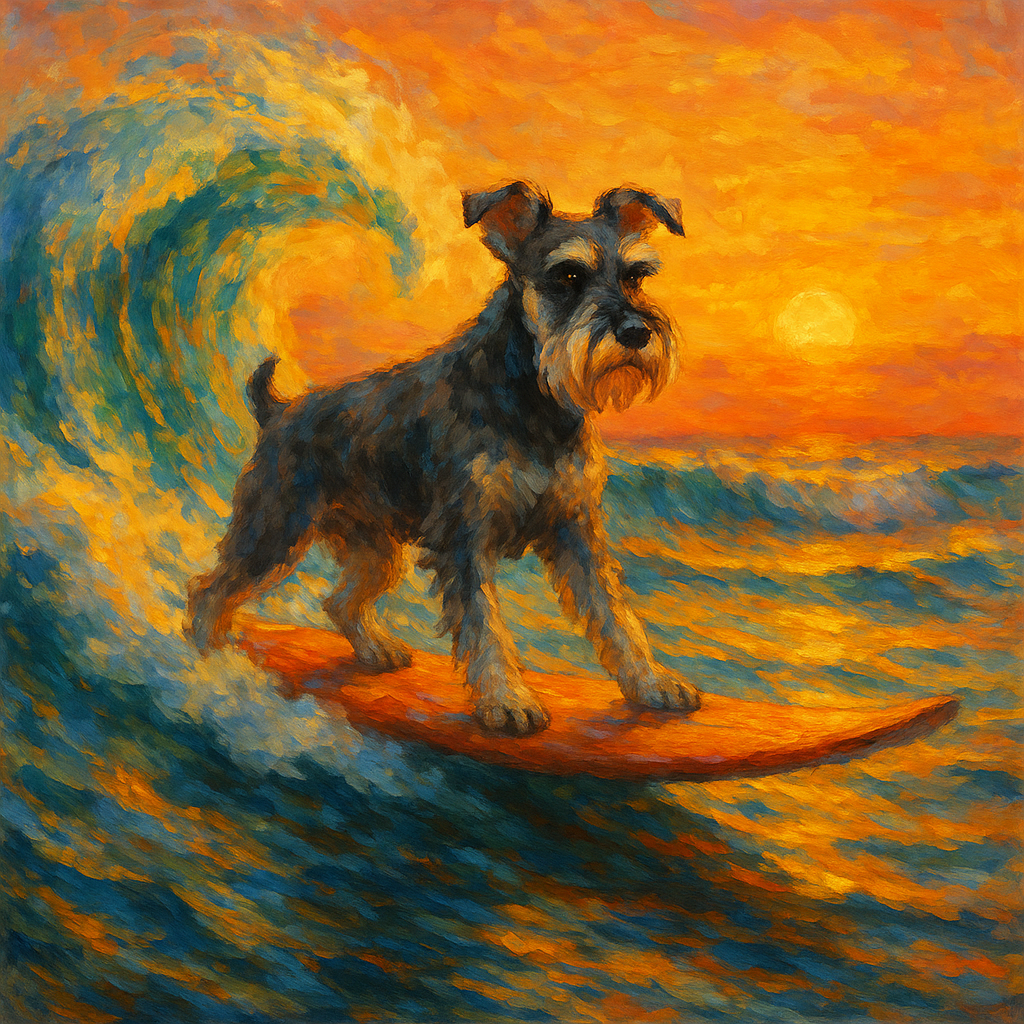

In [18]:
from PIL import Image
from io import BytesIO
import requests, base64

image_response = client.images.generate(
    model="gpt-image-1",
    prompt="Un schnauzer mediano haciendo surf en una ola hawaiana al atardecer, "
           "estilo pintura digital impresionista, colores cálidos.",
    n=1,
    size="1024x1024",
)

img_bytes = base64.b64decode(image_response.data[0].b64_json)
img = Image.open(BytesIO(img_bytes))
img

## 2.2 · Texto → Voz con TTS

Convertimos un fragmento literario en un audio reproducible. Voz `alloy` por defecto; OpenAI ofrece varias (`echo`, `fable`, `nova`, `onyx`, `shimmer`).

In [19]:
from pathlib import Path

audio_dir = Path("audios_generados")
audio_dir.mkdir(exist_ok=True)

texto_a_leer = (
    "En un lugar de la Mancha, de cuyo nombre no quiero acordarme, "
    "no ha mucho tiempo que vivía un hidalgo de los de lanza en astillero, "
    "adarga antigua, rocín flaco y galgo corredor."
)

speech_path = audio_dir / "quijote.mp3"

with client.audio.speech.with_streaming_response.create(
    model="gpt-4o-mini-tts",
    voice="alloy",
    input=texto_a_leer,
) as response:
    response.stream_to_file(speech_path)

print(f"✅ Audio generado: {speech_path}")

from IPython.display import Audio
Audio(speech_path)

✅ Audio generado: audios_generados/quijote.mp3


## 2.3 · Cerrando el círculo · Audio → Texto con Whisper

Le pasamos a Whisper el audio que acabamos de generar y comprobamos si lo transcribe bien. Es la base de cualquier asistente de voz, sistema de subtitulado o análisis de call-center.

In [20]:
with open(speech_path, "rb") as audio_file:
    transcription = client.audio.transcriptions.create(
        model="whisper-1",
        file=audio_file,
    )

print("Texto original :", texto_a_leer)
print()
print("Transcripción  :", transcription.text)

Texto original : En un lugar de la Mancha, de cuyo nombre no quiero acordarme, no ha mucho tiempo que vivía un hidalgo de los de lanza en astillero, adarga antigua, rocín flaco y galgo corredor.

Transcripción  : En un lugar de la Mancha, de cuyo nombre no quiero acordarme, no ha mucho tiempo que vivía un hidalgo, de los de Lanza en Astillero, a Darga Antigua, Drosín Flaco y Galbo Corredor.


> **Lo que acabáis de ver** es exactamente el patrón que se usa en producción para asistentes conversacionales: voz del usuario → Whisper transcribe → LLM responde → TTS habla. Toda la cadena: 30 líneas de código.

---

# Bloque 3 · Inferencia local en tu ordenador

Hasta ahora todo se ha procesado en la nube: tu prompt sale de tu portátil, llega a un datacenter de OpenAI/Anthropic, se procesa y vuelve. Tiene tres problemas:

- **Coste** — cada llamada cuesta dinero.
- **Privacidad** — tus datos salen de tu red.
- **Internet** — sin red, sin LLM.

La buena noticia: en 2025 ya **puedes correr LLMs decentes en tu portátil sin GPU externa**, especialmente si tienes Apple Silicon (M1, M2, M3, M4). Apple desarrolló **MLX**, un framework optimizado para los chips de la serie M.

Vamos a descargar **Phi-3-mini** (un LLM de 3.8B parámetros cuantizado a 4 bits, ocupa ~2.2 GB) y a usarlo localmente.

> Esto solo funciona en macOS con Apple Silicon. Si estás en Windows/Linux o Intel Mac, salta este bloque; en T1-S3 veremos alternativas multiplataforma como Ollama.

In [21]:
import platform

if platform.system() == "Darwin" and platform.machine() == "arm64":
    from mlx_lm import load, generate

    # Cargamos Phi-3-mini-4bit (descarga ~2.2GB la primera vez, luego cachea).
    print("⏳ Cargando Phi-3-mini-4bit en memoria... (primer load tarda ~30s)")
    model, tokenizer = load("mlx-community/Phi-3-mini-4k-instruct-4bit")
    print("✅ Modelo listo. RAM usada: ~3 GB.")
else:
    print("⏭️  No estás en Apple Silicon. Saltamos el bloque local.")
    model, tokenizer = None, None

/Users/manudiaz/Library/CloudStorage/OneDrive-Personal/Escritorio/Manuel/Proyectos/Clases/EBIS/2 - Master en Ingeniería de Automatización con IA Agéntica/Tema 1/Sesión 1/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


⏳ Cargando Phi-3-mini-4bit en memoria... (primer load tarda ~30s)


Fetching 9 files: 100%|██████████| 9/9 [00:51<00:00,  5.77s/it]


✅ Modelo listo. RAM usada: ~3 GB.


In [22]:
if model is not None:
    prompt = tokenizer.apply_chat_template(
        [{"role": "user", "content": "Explícame en 3 frases qué es la IA Generativa, en español."}],
        tokenize=False,
        add_generation_prompt=True,
    )

    respuesta = generate(
        model, tokenizer,
        prompt=prompt,
        max_tokens=200,
        verbose=False,
    )

    print(respuesta)
else:
    print("⏭️  Sin modelo local cargado.")

La IA Generativa es un subcampo de inteligencia artificial que se enfoca en crear nuevas imágenes, sonidos o textos similares a los existentes, utilizando modelos de aprendizaje profundo. Estos modelos, como GANs (Generative Adversarial Networks), aprenden patrones y características de los datos de entrada para generar resultados únicos y creativos. Es una herramienta poderosa en campos como el arte digital, la medicina y la investigación científica.<|end|>


### Comparativa rápida · Cloud vs Local

Lo que cuesta ese mismo prompt en cada sitio:

| Modelo         | Coste por llamada     | Latencia       | Privacidad |
|----------------|-----------------------|----------------|------------|
| GPT-4o cloud   | ~0.0005 USD           | 1-3 s          | Sale a OpenAI |
| Phi-3-mini M4  | 0 USD                 | 1-3 s          | Tu portátil |

Phi-3-mini está bastante por debajo de GPT-4o en calidad, claro. Pero en una **escala intermedia** (Llama 3 70B, Mistral, Qwen) las diferencias se acortan mucho. Lo veremos en sesiones siguientes.

---

# Cierre · ¿Qué nos llevamos?

En menos de 50 líneas de Python hemos:

- Llamado a dos LLMs cloud de proveedores distintos.
- Generado una imagen y un audio a partir de texto.
- Transcrito un audio.
- Cargado un LLM y hecho inferencia **sin internet** en el MacBook.

Esto es **el punto de partida** del Máster. A partir de aquí entramos en:

- **Tema 1 · Sesión 2** — preparación del entorno de desarrollo profesional (Python, venv, Git, VS Code, Postman).
- **Tema 1 · Sesión 3** — proveedores de IA Generativa, alternativas open-source, requisitos de hardware.
- **Tema 2** — fundamentos de ML y Deep Learning, hasta llegar a construir nuestro propio mini-GPT en la Sesión 5.

¿Preguntas?